# Parte I — Self-attention do zero

**DAS410116 — Inteligência Artificial Generativa · UFSC · 2026/2**
**Professor:** Eric A. Antonelo
**Aluno:** Leonardo Coli
**Fontes e uso de IA:** Claude.

Implementação da scaled dot-product attention só com operações elementares do PyTorch (`@`, `.T`, `masked_fill`, `torch.softmax`). Não uso `nn.MultiheadAttention`, `torch.nn.functional.scaled_dot_product_attention` nem módulos de atenção prontos.

O notebook trabalha com **uma única sequência**, sem dimensão de batch.

## 0. Configuração

Célula do starter, sem modificação.

In [1]:
import math
import torch
import matplotlib.pyplot as plt

torch.manual_seed(42)
torch.set_printoptions(precision=4, sci_mode=False)
print("PyTorch version:", torch.__version__)

PyTorch version: 2.14.1+cpu


## 1. Queries, keys e values — 0,50 ponto

Para uma sequência $X\in\mathbb{R}^{L\times d_{model}}$:

$$Q=XW_Q,\qquad K=XW_K,\qquad V=XW_V.$$

In [2]:
L, d_model, d_k, d_v = 6, 8, 4, 5

X = torch.randn(L, d_model)
W_Q = torch.randn(d_model, d_k)
W_K = torch.randn(d_model, d_k)
W_V = torch.randn(d_model, d_v)

# 1.1: projeções lineares, uma linha por token
Q = X @ W_Q
K = X @ W_K
V = X @ W_V

# 1.2: shapes de entradas, projeções e resultados
for name, tensor in [
    ("X", X),
    ("W_Q", W_Q),
    ("W_K", W_K),
    ("W_V", W_V),
    ("Q", Q),
    ("K", K),
    ("V", V),
]:
    print(f"{name:<4} {tuple(tensor.shape)}")

X    (6, 8)
W_Q  (8, 4)
W_K  (8, 4)
W_V  (8, 5)
Q    (6, 4)
K    (6, 4)
V    (6, 5)


### Resposta escrita 1

**Perguntas**

1. Por que $Q$ e $K$ precisam ter a mesma última dimensão?
2. Preveja os shapes da matriz de scores, da matriz de atenção e da saída.

**Respostas**

1. Cada score é um produto interno entre uma query e uma key: $S_{ij}=\mathbf q_i^\top\mathbf k_j=\sum_{c=1}^{d_k}Q_{ic}K_{jc}$.
   Esse produto só existe se os dois vetores tiverem o mesmo comprimento $d_k$. Na forma matricial, o mesmo aparece em
   $Q\,(L_q\times d_k)$ vezes $K^\top\,(d_k\times L_k)$: as dimensões internas precisam coincidir. Os values não têm essa
   restrição. Aqui $d_v=5\neq d_k=4$, porque $V$ só entra depois do softmax, multiplicado por $A\,(L_q\times L_k)$. O que
   $V$ precisa compartilhar com $K$ é o número de linhas $L_k$, já que cada key tem o seu value.
2. Com $L=6$: scores $S=QK^\top/\sqrt{d_k}$ de shape $(6,6)$, atenção $A=\operatorname{softmax}(S)$ também $(6,6)$, e
   saída $O=AV$ de shape $(6,5)=(L,d_v)$. A seção 3 confirma esses shapes com asserts.

## 2. Scaled dot-product attention — 1,25 ponto

$$S=\frac{QK^\top}{\sqrt{d_k}},\qquad
A=\operatorname{softmax}(S),\qquad O=AV.$$

A máscara tem shape `(Lq, Lk)`: `True` significa permitido e `False`, bloqueado. Ela é aplicada nos **scores**,
antes do softmax, e não nos pesos.

In [3]:
def scaled_dot_product_attention(Q, K, V, mask=None, scale=True):
    # Q: (Lq, d_k)
    # K: (Lk, d_k)
    # V: (Lk, d_v)
    # mask: tensor booleano (Lq, Lk), True = permitido
    # retorna: output (Lq, d_v), attention_weights (Lq, Lk)
    assert Q.shape[-1] == K.shape[-1], "Q e K precisam ter o mesmo d_k"
    assert K.shape[0] == V.shape[0], "K e V precisam ter o mesmo número de posições"
    d_k = Q.shape[-1]

    # 2.1: um produto interno por par (query i, key j)
    scores = Q @ K.T  # (Lq, Lk)

    # 2.2: escala 1/sqrt(d_k)
    if scale:
        scores = scores / math.sqrt(d_k)

    # 2.3: posições bloqueadas recebem -inf, então exp(-inf) = 0 depois do softmax.
    # Uma linha totalmente bloqueada viraria NaN; a máscara causal nunca gera essa linha.
    if mask is not None:
        scores = scores.masked_fill(~mask, float("-inf"))

    # 2.4: softmax sobre a dimensão das keys (última)
    attention_weights = torch.softmax(scores, dim=-1)  # (Lq, Lk)

    # 2.5: média ponderada dos values
    output = attention_weights @ V  # (Lq, d_v)

    return output, attention_weights

## 3. Testes de corretude e comprimentos diferentes — 0,75 ponto

Comparações em ponto flutuante usam tolerância, nunca igualdade exata.

In [4]:
output, weights = scaled_dot_product_attention(Q, K, V)
raw_scores = Q @ K.T

# 3.1: shapes esperados
assert raw_scores.shape == (L, L)
assert weights.shape == (L, L)
assert output.shape == (L, d_v)

# 3.2: normalização e não negatividade
row_sums = weights.sum(dim=-1)
nonnegative = bool((weights >= 0).all())

assert torch.allclose(row_sums, torch.ones_like(row_sums), atol=1e-6)
assert nonnegative is True

# Conferência extra: a saída é igual à soma explícita sum_j a_ij v_j
manual = torch.stack([sum(weights[i, j] * V[j] for j in range(L)) for i in range(L)])
assert torch.allclose(output, manual, atol=1e-5)

print(
    "scores:",
    tuple(raw_scores.shape),
    "| pesos:",
    tuple(weights.shape),
    "| saída:",
    tuple(output.shape),
)
print("somas das linhas:", row_sums)
print("menor peso:", weights.min().item())
print("Testes básicos: OK.")

scores: (6, 6) | pesos: (6, 6) | saída: (6, 5)
somas das linhas: tensor([1.0000, 1.0000, 1.0000, 1.0000, 1.0000, 1.0000])
menor peso: 1.469501383160799e-20
Testes básicos: OK.


In [5]:
# 3.3: Lq != Lk (cross-attention: 3 queries consultando 5 pares key-value)
Lq, Lk, d_k_test, d_v_test = 3, 5, 4, 6
Q_test = torch.randn(Lq, d_k_test)
K_test = torch.randn(Lk, d_k_test)
V_test = torch.randn(Lk, d_v_test)

out_test, w_test = scaled_dot_product_attention(Q_test, K_test, V_test)
assert (Q_test @ K_test.T).shape == (Lq, Lk)
assert w_test.shape == (Lq, Lk)
assert out_test.shape == (Lq, d_v_test)
assert torch.allclose(w_test.sum(dim=-1), torch.ones(Lq), atol=1e-6)
assert bool((w_test >= 0).all())

# Máscara retangular (Lq, Lk) também funciona: a query 0 só enxerga as duas primeiras keys
rect_mask = torch.ones(Lq, Lk, dtype=torch.bool)
rect_mask[0, 2:] = False
_, w_rect = scaled_dot_product_attention(Q_test, K_test, V_test, mask=rect_mask)
assert torch.allclose(w_rect[0, 2:], torch.zeros(3), atol=1e-7)
assert torch.allclose(w_rect.sum(dim=-1), torch.ones(Lq), atol=1e-6)

print("pesos:", tuple(w_test.shape), "| saída:", tuple(out_test.shape))
print("pesos com máscara retangular:\n", w_rect)
print("Teste com comprimentos diferentes: OK.")

pesos: (3, 5) | saída: (3, 6)
pesos com máscara retangular:
 tensor([[0.9894, 0.0106, 0.0000, 0.0000, 0.0000],
        [0.3087, 0.1951, 0.3240, 0.1168, 0.0554],
        [0.2839, 0.1686, 0.3706, 0.1178, 0.0590]])
Teste com comprimentos diferentes: OK.


## 4. Máscara causal — 0,50 ponto

Máscara booleana triangular inferior: a query $i$ pode atender a si mesma e às posições anteriores, nunca às futuras.

In [6]:
def causal_mask(seq_len, device=None):
    # 4.1: True no triângulo inferior, diagonal incluída (j <= i)
    mask = torch.tril(torch.ones(seq_len, seq_len, dtype=torch.bool, device=device))
    return mask


mask = causal_mask(L, device=Q.device)
print("Máscara causal:\n", mask.to(torch.int32))

causal_output, causal_weights = scaled_dot_product_attention(Q, K, V, mask=mask)

# 4.2: pesos acima da diagonal principal (j > i) têm de ser zero
future_weights = causal_weights[~mask]
assert torch.allclose(
    future_weights,
    torch.zeros_like(future_weights),
    atol=1e-7,
)
# Conferências extras: linhas continuam somando 1 e a primeira query só vê a si mesma
assert torch.allclose(causal_weights.sum(dim=-1), torch.ones(L), atol=1e-6)
assert torch.allclose(causal_weights[0], torch.eye(L)[0], atol=1e-7)
# A saída na posição i não muda se as posições futuras de V mudarem
V_alt = V.clone()
V_alt[3:] = 100.0
out_alt, _ = scaled_dot_product_attention(Q, K, V_alt, mask=mask)
assert torch.allclose(out_alt[:3], causal_output[:3], atol=1e-6)

print("Pesos com máscara causal:\n", causal_weights)
print("maior peso acima da diagonal:", future_weights.abs().max().item())
print("Teste da máscara causal: OK.")

Máscara causal:
 tensor([[1, 0, 0, 0, 0, 0],
        [1, 1, 0, 0, 0, 0],
        [1, 1, 1, 0, 0, 0],
        [1, 1, 1, 1, 0, 0],
        [1, 1, 1, 1, 1, 0],
        [1, 1, 1, 1, 1, 1]], dtype=torch.int32)
Pesos com máscara causal:
 tensor([[1.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000],
        [0.9999, 0.0001, 0.0000, 0.0000, 0.0000, 0.0000],
        [1.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000],
        [0.9999, 0.0000, 0.0001, 0.0000, 0.0000, 0.0000],
        [0.0000, 0.9882, 0.0115, 0.0003, 0.0000, 0.0000],
        [1.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000]])
maior peso acima da diagonal: 0.0
Teste da máscara causal: OK.


### Resposta escrita 4

**Pergunta.** Por que a máscara causal é necessária ao treinar um modelo de predição do próximo token?

**Resposta**

No treino, a sequência inteira entra de uma vez (teacher forcing), e a saída da posição $i$ tem de prever o token
$i+1$. Sem máscara, a query $i$ pode atender à key $i+1$, ou seja, ler exatamente o token que deveria prever. A loss
cairia copiando a resposta, sem que o modelo aprendesse a prever. Além disso, na inferência os tokens futuros ainda não
existem, então o modelo treinado assim veria em produção uma situação que nunca viu no treino.

Com a máscara triangular inferior, $A_{ij}=0$ para $j>i$. A saída da posição $i$ passa a depender só de $x_0,\dots,x_i$,
e um único forward sobre a sequência inteira equivale a $L$ forwards sobre os prefixos, um para cada posição. A máscara
entra nos scores como $-\infty$, e como $e^{-\infty}=0$, o peso sai exatamente zero, não só pequeno: o maior peso acima da
diagonal foi `0.0`. O teste extra mostra a consequência prática: trocar $V$ nas posições 3 a 5 por 100 não mudou nenhuma
das saídas 0 a 2.

## 5. Por que dividir por $\sqrt{d_k}$? — 0,50 ponto

Comparação com e sem escala para $d_k\in\{8,64,256\}$, usando os mesmos $Q$ e $K$ em cada par. A tabela mostra
o desvio-padrão dos scores, a entropia média das linhas (o máximo, para 6 keys, é $\log 6\approx 1{,}79$) e o maior
peso médio por linha.

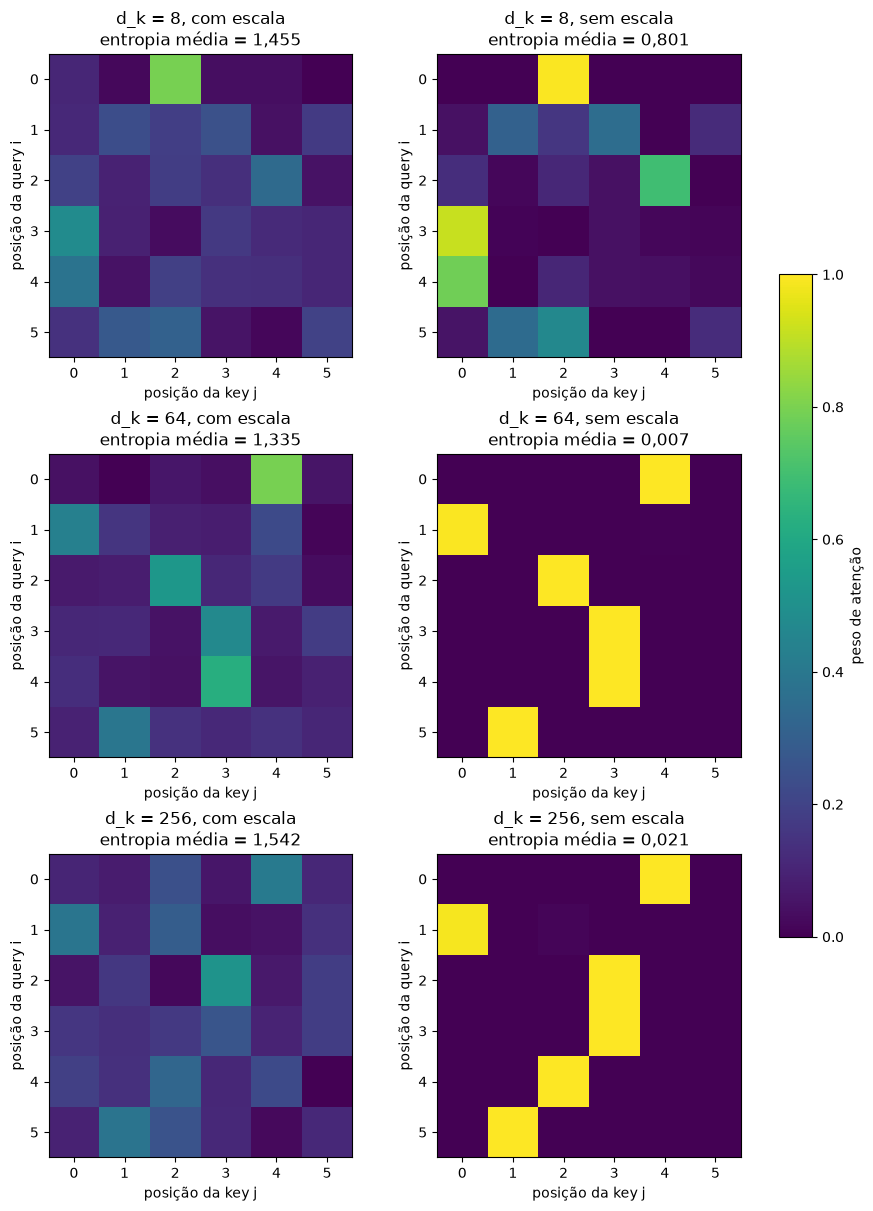

entropia máxima para 6 keys: log 6 = 1.792

 d_k | versão     | std scores | entropia | maior peso
-------------------------------------------------------
   8 | com escala |       1.07 |    1.455 |      0.427
   8 | sem escala |       3.02 |    0.801 |      0.702
  64 | com escala |       1.14 |    1.335 |      0.543
  64 | sem escala |       9.09 |    0.007 |      0.999
 256 | com escala |       1.16 |    1.542 |      0.382
 256 | sem escala |      18.49 |    0.021 |      0.997


In [7]:
def mean_row_entropy(attention_weights, eps=1e-12):
    return -(attention_weights * (attention_weights + eps).log()).sum(dim=-1).mean()


d_k_values = [8, 64, 256]
fig, axes = plt.subplots(len(d_k_values), 2, figsize=(9, 12), constrained_layout=True)
summary = []

for row, current_d_k in enumerate(d_k_values):
    torch.manual_seed(100 + current_d_k)
    Q_exp = torch.randn(6, current_d_k)
    K_exp = torch.randn(6, current_d_k)
    V_exp = torch.randn(6, 3)

    # 5.1: mesmos Q e K, com e sem divisão por sqrt(d_k)
    _, weights_scaled = scaled_dot_product_attention(Q_exp, K_exp, V_exp, scale=True)
    _, weights_unscaled = scaled_dot_product_attention(Q_exp, K_exp, V_exp, scale=False)

    # 5.2: heatmaps com a entropia média no título
    for col, (label, w, s) in enumerate(
        [
            ("com escala", weights_scaled, (Q_exp @ K_exp.T) / math.sqrt(current_d_k)),
            ("sem escala", weights_unscaled, Q_exp @ K_exp.T),
        ]
    ):
        H = mean_row_entropy(w).item()
        ax = axes[row, col]
        im = ax.imshow(w.numpy(), vmin=0, vmax=1, cmap="viridis")
        ax.set_title(
            f"d_k = {current_d_k}, {label}\nentropia média = {H:.3f}".replace(".", ",")
        )
        ax.set_xlabel("posição da key j")
        ax.set_ylabel("posição da query i")
        summary.append(
            (current_d_k, label, s.std().item(), H, w.max(dim=-1).values.mean().item())
        )

fig.colorbar(im, ax=axes, shrink=0.6, label="peso de atenção")
plt.show()

print(f"entropia máxima para 6 keys: log 6 = {math.log(6):.3f}\n")
print(
    f"{'d_k':>4} | {'versão':<10} | {'std scores':>10} | {'entropia':>8} | {'maior peso':>10}"
)
print("-" * 55)
for d, label, sd, H, mx in summary:
    print(f"{d:>4} | {label:<10} | {sd:>10.2f} | {H:>8.3f} | {mx:>10.3f}")

### Resposta escrita 5

**Perguntas**

1. Como a concentração da atenção muda quando `d_k` cresce sem a escala?
2. Por que um softmax concentrado demais pode dificultar a otimização?
3. A escala produziu o comportamento esperado pela teoria?

**Respostas**

1. **Fica muito mais concentrada.** Com componentes independentes de média 0 e variância 1,
   $\operatorname{Var}[\mathbf q^\top\mathbf k]=d_k$, então o desvio-padrão dos scores cresce como $\sqrt{d_k}$. A tabela
   confirma: sem escala o desvio-padrão foi 3,02, 9,09 e 18,49 para $d_k=8$, 64 e 256, próximo de $\sqrt{d_k}=2{,}8$, 8 e
   16. A entropia média das linhas (máximo $\log 6=1{,}79$) cai de 0,801 para 0,007 e 0,021, e o maior peso médio por
   linha sobe de 0,702 para 0,999 e 0,997. Neste sorteio, $d_k=64$ ficou um pouco mais concentrado que $d_k=256$. Com
   só 6 keys, a entropia depende de quanto o maior score se destaca do segundo, e isso varia de sorteio para sorteio.
   Com desvio-padrão de 9 ou de 18, as duas versões já estão praticamente one-hot. A tendência é clara: sem escala,
   quanto maior $d_k$, mais a atenção se concentra numa única key.

2. **Porque o softmax saturado quase não passa gradiente.** Quando um peso vale quase 1 e os outros quase 0, pequenas
   mudanças nos scores quase não mudam os pesos: o softmax está na região plana. O gradiente que volta para $Q$ e $K$
   fica muito pequeno, e as keys que não foram escolhidas quase não recebem sinal para mudar. Na prática, a key que
   ganhou na inicialização tende a continuar ganhando, e o modelo aprende devagar ou não aprende. A Parte I não treina
   nada, então isso é a consequência esperada, e não algo medido aqui. Os slides de *Attention Mechanism* justificam
   a divisão por $\sqrt d$ por manter a variância dos scores em 1, o que evita essa saturação.

3. **Sim.** Com a divisão por $\sqrt{d_k}$, o desvio-padrão dos scores ficou entre 1,07 e 1,16 nos três casos, perto do
   valor 1 previsto pela teoria. A entropia ficou em 1,455, 1,335 e 1,542, e o maior peso médio em 0,427, 0,543 e 0,382,
   sem depender de $d_k$. A atenção fica espalhada, mas ainda seletiva. Dividir por $d_k$ em vez de $\sqrt{d_k}$
   encolheria os scores demais para $d_k$ grande e deixaria a atenção quase uniforme.

## Fontes e uso de IA

- Slides da disciplina: *Transformers 2 — Attention Mechanism*, *Transformers 3 — Multi-head* e *Transformers 4 — Transformer* (Prof. Eric A. Antonelo).
- A. Zhang, Z. C. Lipton, M. Li e A. J. Smola, *Dive into Deep Learning*, cap. 11 (Attention Mechanisms and Transformers), d2l.ai.
- Documentação do PyTorch (`torch.softmax`, `Tensor.masked_fill`, `torch.tril`).
- Assistência de IA: Claude Code (Anthropic), usado na implementação. Executei e conferi todos os resultados.

## Checklist final

- [x] Todos os `TODO` foram completados.
- [x] Todas as asserções passam.
- [x] Os gráficos e as respostas escritas estão visíveis.
- [x] O notebook roda inteiro com *Restart Kernel and Run All*.